# Member 4: Uncertainty and Multi-Horizon Forecasts (Quantile Regression)

**Goal:** Give the portfolio manager an honest 10%-90% range around each forecast, check how often the real price fell inside it (coverage), and measure how forecast skill changes from 1 to 63 trading days.

**What is in this notebook, in order**
1. Load MSFT data and Member 3's out-of-sample predictions (`outputs/member3_predictions.csv`)
2. Helper functions ie. quantile regression, range scores, Gradient Boosting settings
3. 1-day range: does Member 3's model help the quantile regression?
4. Walk-forward test at 1, 5, 21 and 63 days (skill, DM test, coverage)
5. Today's forecasts for all four horizons
6. Save `data/forecast_intermediate.csv` for Power BI (Member 5)
7. Chart of skill and reliability against the horizon

**How to read the tables**
- Coverage should be about 0.80 for a 10%-90% range. Lower means the range is too narrow (overconfident).
- Out-of-sample R2 above 0 means better than naive. Naive scores exactly 0.
- The naive forecast (no change in price) is in every table as the benchmark.

In [1]:
# Setup and load Member 3's predictions
import time, warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor

import tslab.config as cfg
from tslab.data import load_market_data
from tslab.features import make_dataset, ALL_FEATURES
from tslab.validation import walk_forward_splits
from tslab.metrics import rmse, mae, out_of_sample_r2, directional_accuracy, diebold_mariano, dm_verdict

warnings.filterwarnings("ignore")
HORIZONS, LOW_Q, HIGH_Q = [1, 5, 21, 63], 0.10, 0.90

frame = load_market_data(verbose=False)
m3 = pd.read_csv(cfg.OUTPUT_DIR / "member3_predictions.csv", index_col=0, parse_dates=True)   # from member3_intermediate.ipynb
print(m3.shape, m3.index[0].date(), "to", m3.index[-1].date())

(1781, 5) 2019-10-08 to 2026-11-06


Member 3's file has 1,781 out-of-sample 1-day predictions (Ridge, ARIMA and Gradient Boosting) from 8 October 2019 to 6 November 2026. We read it here and use it for the 1-day range and for the model columns in the final CSV.

In [2]:
# Helpers
def fit_quantiles(X_train, y_train, X_test):
    """10th and 90th percentile of the return by linear quantile regression (statsmodels QuantReg)."""
    Xtr, Xte = sm.add_constant(X_train, has_constant="add"), sm.add_constant(X_test, has_constant="add")
    lo = sm.QuantReg(y_train, Xtr).fit(q=LOW_Q, max_iter=5000).predict(Xte)
    hi = sm.QuantReg(y_train, Xtr).fit(q=HIGH_Q, max_iter=5000).predict(Xte)
    return np.minimum(lo, hi), np.maximum(lo, hi)           # stops the two lines from crossing

def pinball(y, q, tau):
    d = np.asarray(y) - np.asarray(q)
    return float(np.mean(np.maximum(tau * d, (tau - 1) * d)))

def range_scores(y, lo, hi):
    return {"Coverage (target 0.80)": float(((y >= lo) & (y <= hi)).mean()),
            "Average width (% of price)": float((np.exp(hi) - np.exp(lo)).mean() * 100),
            "Pinball loss 10%": pinball(y, lo, LOW_Q), "Pinball loss 90%": pinball(y, hi, HIGH_Q)}

def make_gb():   # exactly the Gradient Boosting settings used by Member 3
    return GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05,
                                     subsample=0.8, random_state=cfg.SEED)

## Step 1: A 10%-90% range for the next day

**Quantile regression** predicts a chosen percentile of the return instead of the average. We fit two models, one for the 10th and one for the 90th percentile. The range between them should contain the true return about 80% of the time.

The range is fitted by walk-forward testing, which never uses the future:
- It starts after the first 252 out-of-sample days of Member 3's predictions.
- It is refitted every 63 days using only the days before the test block.

We compare four ranges. The first is the **naive range**: the 10th and 90th percentile of past returns, which ignores the current market conditions. The other three are quantile regressions that use the 21-day volatility, with or without Member 3's ARIMA or Gradient Boosting forecast as an extra predictor.

In [3]:
# 1-day range: does Member 3's model help the quantile regression?
d1 = make_dataset(frame, horizon=1).dropna(subset=["target_return"])
a = d1.join(m3[["actual", "ARIMA", "GradientBoosting"]], how="inner")
assert np.allclose(a["target_return"], a["actual"])        # Member 3's file lines up with our dataset

variants = {"Naive range (past 10%-90% of returns)": None,
            "QuantReg: volatility only": ["vol_21d"],
            "QuantReg: volatility + ARIMA forecast": ["vol_21d", "ARIMA"],
            "QuantReg: volatility + Gradient Boosting forecast": ["vol_21d", "GradientBoosting"]}
WARM, BLOCK = 252, 63          # learn from the first 252 out-of-sample days, then refit every 63 days
rows = {}
for name, cols in variants.items():
    lo, hi = np.full(len(a), np.nan), np.full(len(a), np.nan)
    for start in range(WARM, len(a), BLOCK):
        tr, te = np.arange(start), np.arange(start, min(start + BLOCK, len(a)))
        ytr = a["actual"].iloc[tr].values
        if cols is None:
            lo[te], hi[te] = np.quantile(ytr, LOW_Q), np.quantile(ytr, HIGH_Q)
        else:
            lo[te], hi[te] = fit_quantiles(a[cols].iloc[tr].values, ytr, a[cols].iloc[te].values)
    ok = ~np.isnan(lo)
    rows[name] = range_scores(a["actual"].values[ok], lo[ok], hi[ok])
print(f"{ok.sum()} test days, from {a.index[WARM].date()}")
pd.DataFrame(rows).T.round(5)

1529 test days, from 2020-10-07


,Coverage (target 0.80),Average width (% of price),Pinball loss 10%,Pinball loss 90%
Naive range (past 10%-90% of returns),0.83126,4.31993,0.00313,0.00305
QuantReg: volatility only,0.81360,4.09072,0.00307,0.00296
QuantReg: volatility + ARIMA forecast,0.81360,4.02633,0.00308,0.00301
QuantReg: volatility + Gradient Boosting forecast,0.81687,4.12931,0.00307,0.00296


### What the 1-day range table shows (1,529 test days)

| Range | Coverage | Average width (% of price) |
|:--|--:|--:|
| Naive range (past 10%-90% of returns) | 83.1% | 4.32 |
| QuantReg: volatility only | 81.4% | 4.09 |
| QuantReg: volatility + ARIMA forecast | 81.4% | 4.03 |
| QuantReg: volatility + Gradient Boosting forecast | 81.7% | 4.13 |

All four ranges contain the true return close to the 80% target. The quantile regression ranges are a little narrower than the naive range for about the same coverage, because they widen when volatility is high and narrow when it is calm. The pinball loss, which scores how well each percentile is estimated (lower is better), is also slightly lower for the quantile regressions (about 0.00307 and 0.00296) than for the naive range (0.00313 and 0.00305). Adding Member 3's ARIMA or Gradient Boosting forecast changes the range very little (width 4.03% to 4.13% against 4.09% without them). This is consistent with Member 3's result that those models do not predict the direction of the return. So for all horizons we use **volatility only** in the quantile regression, which keeps the four horizons consistent.

## Step 2: How does skill change from 1 to 63 days?

We use the **direct method**: a separate model for each horizon h (1, 5, 21 and 63 trading days), trained on the return from today to h days ahead.

Because the target for h = 21 looks 21 days ahead, neighbouring rows share 20 days of the same return. We therefore leave a **gap of h - 1 rows** between the training data and each test block, so that no training label reaches into the test period (rule: never use future data). The walk-forward splits are the same as the other members use (1,000 initial training rows, 63-day test blocks).

For each horizon we measure:
- The point forecast from Gradient Boosting (the same settings as Member 3), against the naive forecast, in dollars and in returns
- The Diebold-Mariano test against the naive forecast, adjusted for overlapping horizons
- The quantile regression 10%-90% range and its coverage, against the naive range

In [4]:
# Direct multi-horizon walk-forward (gap = h - 1 so labels never overlap the test block)
skill, backtests, t0 = {}, [], time.time()
for h in HORIZONS:
    dh = make_dataset(frame, horizon=h).dropna(subset=["target_return"])
    X, y = dh[ALL_FEATURES], dh["target_return"]
    splits = list(walk_forward_splits(len(dh), cfg.INITIAL_TRAIN, cfg.TEST_SIZE, gap=h - 1))
    ml, lo, hi, nlo, nhi = (pd.Series(np.nan, index=dh.index) for _ in range(5))
    for tr, te in splits:
        ytr = y.iloc[tr].values
        ml.iloc[te] = make_gb().fit(X.iloc[tr].values, ytr).predict(X.iloc[te].values)
        lo.iloc[te], hi.iloc[te] = fit_quantiles(dh[["vol_21d"]].iloc[tr].values, ytr, dh[["vol_21d"]].iloc[te].values)
        nlo.iloc[te], nhi.iloc[te] = np.quantile(ytr, LOW_Q), np.quantile(ytr, HIGH_Q)
    ok = ml.notna()
    yr, p0, ph, mp = y[ok], dh.loc[ok, "close"], dh.loc[ok, "target_close"], ml[ok]
    stat, pval = diebold_mariano(yr, mp, np.zeros(len(yr)), horizon=h)     # model vs naive; positive = model worse
    q, nq = range_scores(yr.values, lo[ok].values, hi[ok].values), range_scores(yr.values, nlo[ok].values, nhi[ok].values)
    skill[h] = {"Test days": int(ok.sum()),
                "RMSE naive ($)": rmse(ph, p0), "RMSE model ($)": rmse(ph, p0 * np.exp(mp)),
                "MAE naive ($)": mae(ph, p0), "MAE model ($)": mae(ph, p0 * np.exp(mp)),
                "Out-of-sample R2": out_of_sample_r2(yr, mp),
                "Directional accuracy": directional_accuracy(yr, mp), "Share of up-moves (base rate)": float((yr > 0).mean()),
                "DM p-value vs naive": pval, "DM verdict": dm_verdict(stat, pval),
                "Coverage QuantReg": q["Coverage (target 0.80)"], "Coverage naive range": nq["Coverage (target 0.80)"],
                "Width QuantReg (% price)": q["Average width (% of price)"], "Width naive range (% price)": nq["Average width (% of price)"]}
    pos = frame.index.get_indexer(dh.index[ok]) + h                          # row of the day being forecast
    backtests.append(pd.DataFrame({
        "record_type": "backtest", "forecast_made_on": dh.index[ok], "date": frame.index[pos], "horizon_days": h,
        "actual_close": ph.values, "naive_forecast": p0.values, "ml_forecast": (p0 * np.exp(mp)).values,
        "lower_10": (p0 * np.exp(lo[ok])).values, "upper_90": (p0 * np.exp(hi[ok])).values}))
    print(f"horizon {h:>2} days done ({time.time() - t0:.0f} s)")

skill = pd.DataFrame(skill).T
skill.index.name = "Horizon (trading days)"
skill.T

horizon  1 days done (74 s)
horizon  5 days done (151 s)
horizon 21 days done (218 s)
horizon 63 days done (275 s)


Horizon (trading days),1,5,21,63
Test days,1781,1773,1741,1657
RMSE naive ($),5.7884,12.636839,25.498151,45.525926
RMSE model ($),6.252419,13.386729,29.320629,53.449454
MAE naive ($),3.99395,9.002508,18.81245,34.474116
MAE model ($),4.281132,9.594345,22.016177,41.618284
Out-of-sample R2,-0.123221,-0.122082,-0.223542,-0.24137
Directional accuracy,0.517125,0.517766,0.53475,0.601086
Share of up-moves (base rate),0.529478,0.57868,0.593912,0.658419
DM p-value vs naive,0.000153,0.003042,0.021119,0.19342
DM verdict,Significantly WORSE than naive,Significantly WORSE than naive,Significantly WORSE than naive,No significant difference


### What the multi-horizon table shows

| Horizon (trading days) | 1 | 5 | 21 | 63 |
|:--|--:|--:|--:|--:|
| Test days | 1,781 | 1,773 | 1,741 | 1,657 |
| RMSE of the naive forecast ($) | 5.79 | 12.64 | 25.50 | 45.53 |
| RMSE of the model ($) | 6.25 | 13.39 | 29.32 | 53.45 |
| Out-of-sample R2 | -0.123 | -0.122 | -0.224 | -0.241 |
| Directional accuracy | 51.7% | 51.8% | 53.5% | 60.1% |
| Share of up-moves (base rate) | 52.9% | 57.9% | 59.4% | 65.8% |
| DM p-value vs naive | 0.0002 | 0.003 | 0.021 | 0.193 |
| DM verdict | Significantly worse | Significantly worse | Significantly worse | No significant difference |
| Coverage, quantile regression (target 80%) | 77.9% | 73.9% | 67.5% | 61.6% |
| Coverage, naive range | 75.2% | 73.2% | 67.0% | 61.7% |
| Width of the range (% of price) | 3.9 | 7.8 | 14.4 | 23.2 |

**Skill.** The model does not beat the naive forecast at any horizon. Its dollar RMSE is 8%, 6%, 15% and 17% higher than naive. Its out-of-sample R2 is about -0.12 at 1 and 5 days and roughly doubles to -0.22 and -0.24 at 21 and 63 days. At 63 days the DM test is not significant (p = 0.19), but that is because there are only about 26 independent quarters in the test period, not because the model improved. A long horizon has fewer independent observations, so a result there deserves more suspicion, not less.

**Direction.** The 60.1% directional accuracy at 63 days looks impressive but is lower than the 65.8% of 63-day periods in which MSFT simply went up. A rule that always says "up" would have scored higher than the model. At the shorter horizons the model's directional accuracy (51.7% to 53.5%) is also below the share of up-moves for 5 and 21 days (57.9% and 59.4%).

**Uncertainty.** The range grows from 3.9% of the price at 1 day to 23.2% at 63 days. That is about 6 times wider, less than the 7.9 times (the square root of 63) that independent daily moves would give, which suggests daily moves are not fully independent over a quarter.

**Coverage.** The "80%" ranges are too narrow, and the problem grows with the horizon: the true price fell inside them 77.9%, 73.9%, 67.5% and 61.6% of the time. The naive range is just as narrow (75.2%, 73.2%, 67.0% and 61.7%), so the fault lies in how much markets can move beyond what past data show, not in the quantile regression. The portfolio manager should read the 63-day "80% range" as closer to a 60% range.

## Step 3: Today's forecasts at 1, 5, 21 and 63 days

We train the final models on all the history and apply them to today's predictors (the last row of the data, 9 November 2026). The central forecast is Gradient Boosting and the range is the quantile regression. The target date is the last date plus h business days, so it ignores public holidays.

In [5]:
# Today's 1, 5, 21 and 63-day forecasts (final models trained on all history)
last_close, last_date = float(frame["Close"].iloc[-1]), frame.index[-1]
live = []
for h in HORIZONS:
    dh = make_dataset(frame, horizon=h)
    today, train = dh.iloc[[-1]], dh.dropna(subset=["target_return"])
    ytr = train["target_return"].values
    point = make_gb().fit(train[ALL_FEATURES].values, ytr).predict(today[ALL_FEATURES].values)[0]
    l, u = fit_quantiles(train[["vol_21d"]].values, ytr, today[["vol_21d"]].values)
    live.append({"record_type": "forecast", "forecast_made_on": last_date, "date": last_date + pd.offsets.BDay(h),
                 "horizon_days": h, "actual_close": np.nan, "naive_forecast": last_close,
                 "ml_forecast": last_close * np.exp(point), "lower_10": last_close * np.exp(l[0]), "upper_90": last_close * np.exp(u[0])})
live = pd.DataFrame(live)
live.round(2)

,record_type,forecast_made_on,date,horizon_days,actual_close,naive_forecast,ml_forecast,lower_10,upper_90
0,forecast,2026-11-09,2026-11-10,1,NaN,545.18,543.69,533.08,559.11
1,forecast,2026-11-09,2026-11-16,5,NaN,545.18,564.26,520.22,572.17
2,forecast,2026-11-09,2026-12-08,21,NaN,545.18,548.92,506.54,608.40
3,forecast,2026-11-09,2027-02-04,63,NaN,545.18,578.24,505.86,670.01


### Reading today's forecasts (last close 545.18 on 9 November 2026)

| Horizon | Target date | Naive | Model forecast | 10%-90% range |
|:--|:--|--:|--:|:--|
| 1 day | 10 Nov 2026 | 545.18 | 543.69 | 533.08 - 559.11 |
| 5 days | 16 Nov 2026 | 545.18 | 564.26 | 520.22 - 572.17 |
| 21 days | 8 Dec 2026 | 545.18 | 548.92 | 506.54 - 608.40 |
| 63 days | 4 Feb 2027 | 545.18 | 578.24 | 505.86 - 670.01 |

These forecasts should be used with care. The model was worse than naive at every horizon in the walk-forward test, so its central forecast has no proven value over "the price stays where it is". The central forecast and the range also come from different models (Gradient Boosting and quantile regression), which is why the 5-day forecast (564.26) sits near the top of its range (520.22 - 572.17). The range is the more useful part: it shows how far the price could plausibly move. Given the coverage results above, the true chance of landing inside the 63-day range is closer to 60% than 80%.

## Step 4: Save the results for Power BI

We save one file, `data/forecast_intermediate.csv`, with every out-of-sample forecast at the four horizons plus today's forecasts. Columns:

| Column | Meaning |
|:--|:--|
| `record_type` | `backtest` (past, with the real price) or `forecast` (today's forecast) |
| `forecast_made_on` | The day the forecast was made |
| `date` | The day being forecast |
| `horizon_days` | 1, 5, 21 or 63 (use as a slicer in Power BI) |
| `actual_close` | The real closing price (blank for `forecast` rows) |
| `naive_forecast` | Naive forecast: the price on `forecast_made_on` |
| `ridge_forecast`, `arima_forecast` | Member 3's 1-day models as prices (blank for other horizons) |
| `ml_forecast` | Gradient Boosting forecast as a price |
| `lower_10`, `upper_90` | The quantile regression 10%-90% range |
| `inside_range` | 1 if the real price was inside the range, otherwise 0 |

In [6]:
# Save ./data/forecast_intermediate.csv
bt = pd.concat(backtests, ignore_index=True)
m3_close = frame["Close"].reindex(bt["forecast_made_on"]).values
for col, name in [("ridge_forecast", "Ridge"), ("arima_forecast", "ARIMA")]:        # Member 3's 1-day models, as prices
    pred = m3[name].reindex(bt["forecast_made_on"]).values
    bt[col] = np.where(bt["horizon_days"] == 1, m3_close * np.exp(pred), np.nan)

out = pd.concat([bt, live], ignore_index=True)
out["inside_range"] = np.where(out["actual_close"].notna(),
                               ((out["actual_close"] >= out["lower_10"]) & (out["actual_close"] <= out["upper_90"])).astype(float), np.nan)
out = out[["record_type", "forecast_made_on", "date", "horizon_days", "actual_close", "naive_forecast", "ridge_forecast",
           "arima_forecast", "ml_forecast", "lower_10", "upper_90", "inside_range"]]
out = out.sort_values(["horizon_days", "date"]).reset_index(drop=True)
out.to_csv(cfg.DATA_DIR / "forecast_intermediate.csv", index=False)
print("Saved", out.shape, "to", cfg.DATA_DIR / "forecast_intermediate.csv")
out.groupby("horizon_days")["inside_range"].mean().round(3)

Saved (6956, 12) to C:\Users\KAT\OneDrive\Documents\BI LAB WORK\timeseries-b3\timeseries-b3\data\forecast_intermediate.csv


horizon_days
1     0.779
5     0.739
21    0.675
63    0.616
Name: inside_range, dtype: float64

The file has 6,956 rows (6,952 back-test rows and 4 forecast rows). The share of rows with `inside_range = 1` matches the coverage in the table above (0.779, 0.739, 0.675 and 0.616), which confirms the CSV and the table agree.

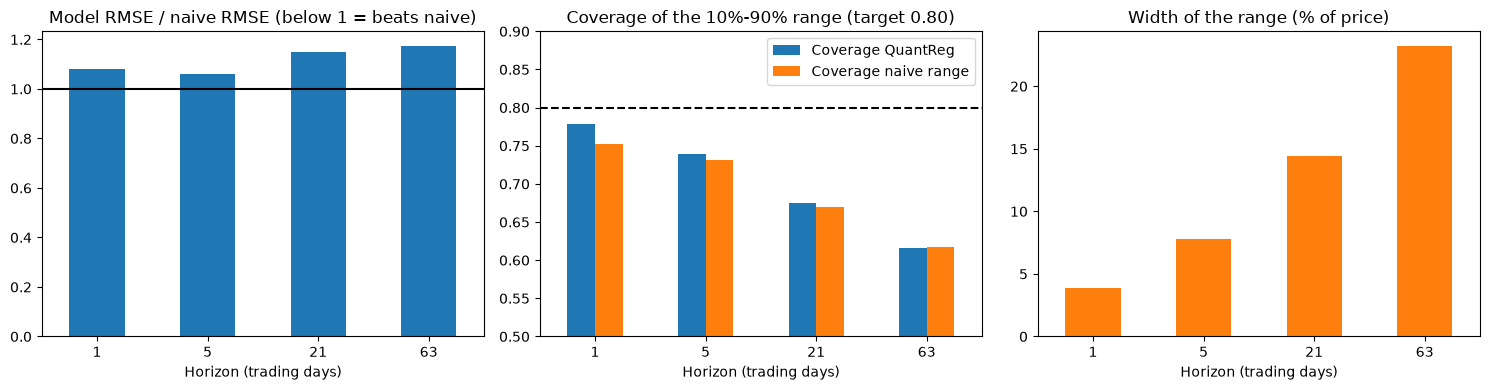

In [7]:
# Chart: how skill and reliability change with the horizon
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
(skill["RMSE model ($)"] / skill["RMSE naive ($)"]).plot.bar(ax=ax[0], color="tab:blue")
ax[0].axhline(1, color="black"); ax[0].set_title("Model RMSE / naive RMSE (below 1 = beats naive)")
skill[["Coverage QuantReg", "Coverage naive range"]].plot.bar(ax=ax[1])
ax[1].axhline(0.8, color="black", linestyle="--"); ax[1].set_title("Coverage of the 10%-90% range (target 0.80)"); ax[1].set_ylim(0.5, 0.9)
skill["Width QuantReg (% price)"].plot.bar(ax=ax[2], color="tab:orange"); ax[2].set_title("Width of the range (% of price)")
for x in ax: x.set_xlabel("Horizon (trading days)"); x.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## Summary

- **Skill:** Gradient Boosting did not beat the naive forecast at 1, 5, 21 or 63 days. It was significantly worse at 1, 5 and 21 days, and its out-of-sample R2 fell from -0.12 to -0.24 as the horizon grew. The apparent success at 63 days (60% directional accuracy) is lower than the 65.8% base rate of upward quarters.
- **Uncertainty:** Quantile regression gives a range that is narrower than the naive range for about the same coverage, but both ranges are too narrow. The "80%" range covered only 77.9%, 73.9%, 67.5% and 61.6% of outcomes at 1, 5, 21 and 63 days.
- **Advice for the portfolio manager:** Do not rely on the point forecast; the naive forecast is as good or better. Use the range to size risk, and treat the 63-day range as roughly a 60% range.
- **Files:** `data/forecast_intermediate.csv` (for Member 5's Power BI dashboard).